# Лабораторная работа №2. Кластеризация

## Цель работы

Изучить методы кластеризации данных, определить оптимальное количество кластеров, обучить модель K-Means и оценить качество кластеризации.

## Задачи

1. Загрузить данные из Excel-файла.
2. Построить диаграмму рассеяния.
3. Определить оптимальное количество кластеров.
4. Обучить модель K-Means.
5. Оценить качество кластеризации.
6. Визуализировать полученные результаты.

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [26]:
data = pd.read_excel("dataset/lab2-05.xlsx", header=None)

data = data.iloc[1:, :]
data.columns = ["x", "y"]

data["x"] = pd.to_numeric(data["x"], errors="coerce")
data["y"] = pd.to_numeric(data["y"], errors="coerce")
data = data.dropna()

X = data[["x", "y"]].to_numpy()

print("Количество объектов:", len(X))
print("Пропущенные значения:", data.isna().sum().sum())

display(data.head())
print(data.describe())

Количество объектов: 1000
Пропущенные значения: 0


,x,y
1,2.139187,0.155126
2,0.400514,-0.958325
3,1.693747,-1.456162
4,1.124378,-7.898880
5,0.323725,-0.774986


                 x            y
count  1000.000000  1000.000000
mean      1.177386    -3.478515
std       1.140751     3.487302
min      -2.358594   -11.032457
25%       0.400303    -7.496222
50%       1.181702    -1.917875
75%       1.957442    -0.784856
max       4.953489     1.793348


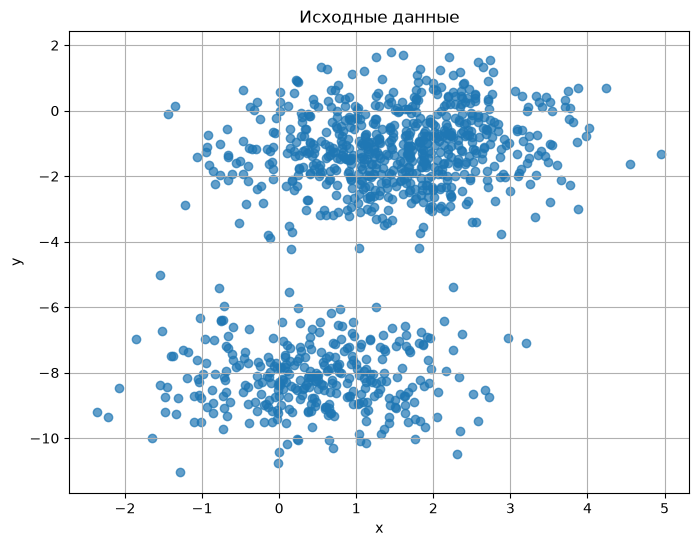

In [27]:
plt.figure(figsize=(8, 6))

plt.scatter(data["x"], data["y"], alpha=0.7)

plt.title("Исходные данные")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.show()

## Определение оптимального количества кластеров

Для выбора количества кластеров используем два метода:

- Метод локтя — анализируем, как изменяется сумма квадратов расстояний до центров кластеров (inertia).
- Коэффициент силуэта — оцениваем, насколько хорошо объекты разделены на кластеры.

Чем выше коэффициент силуэта, тем лучше разделение кластеров в рамках этой метрики.

In [28]:
max_k = min(10, len(X) - 1)

if max_k < 2:
    raise ValueError("Для кластеризации необходимо минимум 2 объекта.")

k_values = range(2, max_k + 1)

inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)

    inertias.append(model.inertia_)

    if 1 < len(np.unique(labels)) < len(X):
        score = silhouette_score(X, labels)
    else:
        score = np.nan

    silhouette_scores.append(score)

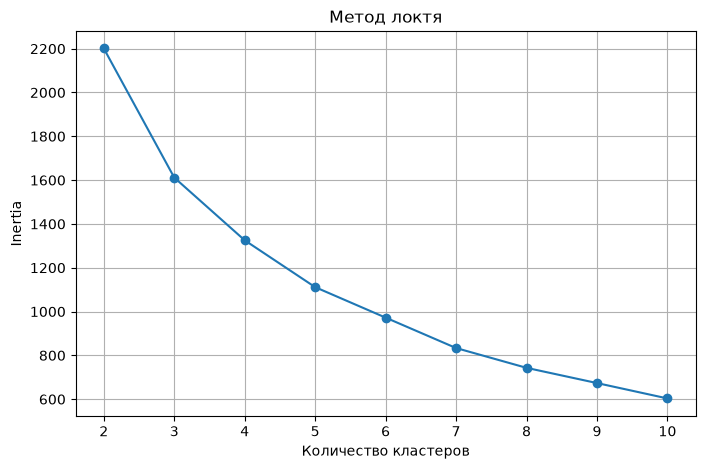

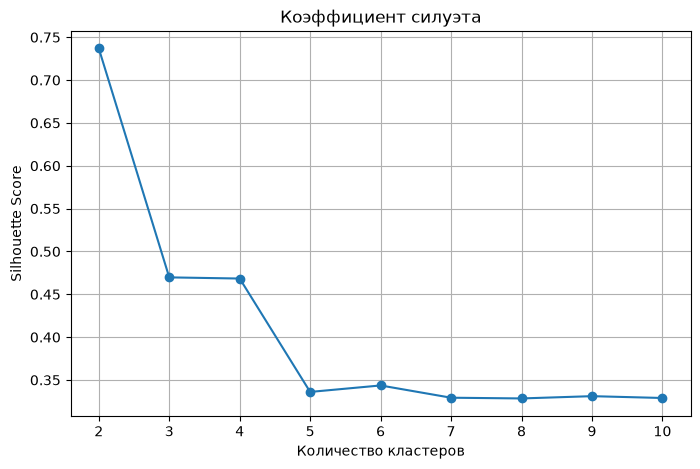

In [29]:
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Метод локтя")
plt.xlabel("Количество кластеров")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.title("Коэффициент силуэта")
plt.xlabel("Количество кластеров")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [ ]:
# Выбираем количество кластеров с наибольшим коэффициентом силуэта
valid_scores = [
    (k, score)
    for k, score in zip(k_values, silhouette_scores)
    if np.isfinite(score)
]

if not valid_scores:
    raise ValueError(
        "Не удалось определить оптимальное количество кластеров. "
        "Проверьте исходные данные."
    )

best_k, best_score = max(valid_scores, key=lambda item: item[1])

print("Оптимальное количество кластеров:", best_k)
print("Лучший коэффициент силуэта:", round(best_score, 4))

Оптимальное количество кластеров: 2
Лучший коэффициент силуэта: 0.7369


## Обучение модели K-Means

Разделим данные на обучающую и тестовую выборки.

Модель будет обучена на обучающей выборке. После этого проверим, как она распределяет объекты тестовой выборки по кластерам.

In [21]:
X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

print("Размер обучающей выборки:", len(X_train))
print("Размер тестовой выборки:", len(X_test))

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

kmeans.fit(X_train)

Размер обучающей выборки: 800
Размер тестовой выборки: 200


,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 2)","[[ 1.

In [22]:
test_labels = kmeans.predict(X_test)

print("Количество кластеров:", best_k)

n_test_clusters = len(np.unique(test_labels))

if 1 < n_test_clusters < len(X_test):
    silhouette = silhouette_score(X_test, test_labels)
    db_score = davies_bouldin_score(X_test, test_labels)

    print("Коэффициент силуэта на тестовой выборке:",
          round(silhouette, 4))
    print("Индекс Дэвиса — Болдина:",
          round(db_score, 4))
else:
    print(
        "На тестовой выборке недостаточно разных кластеров "
        "для расчёта метрик качества."
    )

Количество кластеров: 2
Коэффициент силуэта на тестовой выборке: 0.7402
Индекс Дэвиса — Болдина: 0.3531


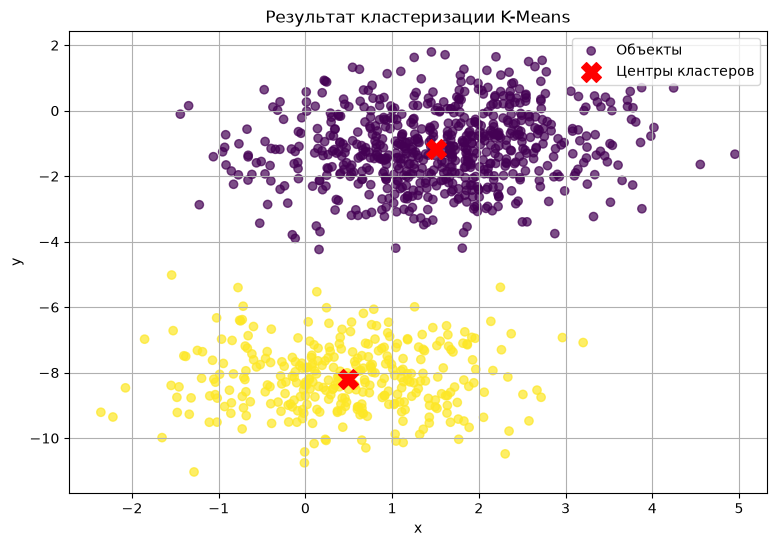

In [ ]:
# Определяем принадлежность всех объектов кластерам
all_labels = kmeans.predict(X)

plt.figure(figsize=(9, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=all_labels,
    cmap="viridis",
    alpha=0.7,
    label="Объекты"
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Центры кластеров"
)

plt.title("Результат кластеризации K-Means")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

In [24]:
cluster_counts = pd.Series(all_labels).value_counts().sort_index()

print("Количество объектов в каждом кластере:")

for cluster, count in cluster_counts.items():
    print(f"Кластер {cluster}: {count} объектов")

Количество объектов в каждом кластере:
Кластер 0: 667 объектов
Кластер 1: 333 объектов


## Вывод

В ходе лабораторной работы была выполнена кластеризация данных с использованием алгоритма K-Means.

Данные были загружены из Excel-файла и представлены в виде диаграммы рассеяния. Оптимальное количество кластеров было выбрано на основе анализа метода локтя и коэффициента силуэта.

После выбора количества кластеров модель была обучена на обучающей выборке и проверена на тестовой выборке. Результаты кластеризации представлены на графике, где разными цветами обозначены кластеры, а красными крестами — их центры.

Таким образом, была изучена работа алгоритма K-Means и выполнена визуализация результатов кластеризации.